In [1]:
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader, Dataset, random_split
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from torchmetrics.classification import F1Score


import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
# import seaborn as sns

from sklearn.metrics import ConfusionMatrixDisplay

from tqdm.notebook import trange, tqdm

import random
import time

random.seed(42)

OUT_DIR = "LSTMOutputs/"
# plt.style.use('seaborn-v0_8-darkgrid')
# sns.set_palette('husl')
torch.manual_seed(42)

In [18]:
# Hyperparamters
learning_rate = 1e-3
# n_epochs = 20
n_epochs = 10
batch_size = 32


In [3]:
label_mapping = {
    "LTR": 0,
    "Non-LTR/LINE": 1,
    "SINE": 2,
    "TIR": 3,
    "Helitron": 4,
    "Crypton": 5,
    "DIRS": 6,
    "Penelope-like Element/PLE": 7
    # "Maverick": 8
}

index_to_label = {number: name for name, number in label_mapping.items()}

sequence_encoding = {
    'A': [1, 0, 0, 0],
    'C': [0, 1, 0, 0],
    'G': [0, 0, 1, 0],
    'T': [0, 0, 0, 1]
}


In [4]:
""" Padding code from GLARE -> they used 4096 as their max_length """

# Random crop for training augmentation
# if self.augment and len(sequence) > self.max_length:
#     start = random.randint(0, len(sequence) - self.max_length)
#     sequence = sequence[start : start + self.max_length]

# # Reverse-complement augmentation (stochastic, training only).
# if self.rc_augment and random.random() < 0.5:
#     sequence = sequence.translate(RC_MAP)[::-1]

# encoding = self.tokenizer(
#     sequence,
#     return_tensors="pt",
#     padding="max_length",
#     truncation=True,
#     max_length=self.max_length,
#     pad_to_multiple_of=128,
# )

' Padding code from GLARE -> they used 4096 as their max_length '

In [5]:
# 4096 is what GLARE used.
# MAX_SEQ_LENGTH = 4096
# using 500 because it's soo slow
MAX_SEQ_LENGTH = 500

def custom_collate_fn(batch):
    """ Custom collate function for padding sequences up to the length of the longest sequence in the batch
    also returns the lengths of the sequences prior to padding """

    sequences, labels = zip(*batch)
    padded_sequences = pad_sequence(sequences, batch_first=True)
    lengths = torch.tensor([len(s) for s in sequences])
    
    return padded_sequences, lengths, torch.stack(labels)


def one_hot(sequence):
    encoded = []
    for nucleotide in sequence:
        encoded.append(sequence_encoding.get(nucleotide, [0,0,0,0]))
    return torch.tensor(encoded, dtype=torch.float32)


class CSVDataset(Dataset):
    
    def __init__(self, csv_file, max_length=MAX_SEQ_LENGTH, train=False):

        df = pd.read_csv(csv_file)

        df = df[df['TE_Order'] != 'Maverick']
        
        self.sequences = [one_hot(s) for s in df["sequence_content"]]
        self.max_length = max_length
        self.train = train

        print(f"Longest sequence: {df["sequence_content"].str.len().max()}")
        print(f"Shortest sequence: {df["sequence_content"].str.len().min()}")
        print(f"Mean sequence length: {df["sequence_content"].str.len().mean()}")
        
        self.encoded_labels = df["TE_Order"].map(label_mapping)
        assert self.encoded_labels.notna().all(), df.loc[self.encoded_labels.isna(), "TE_Order"].unique()
        
        # self.X = torch.tensor(encoded_sequences, dtype=torch.float32)
        self.y = torch.tensor(self.encoded_labels, dtype=torch.long)
    
    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]

        if len(sequence) > self.max_length:
            start = 0

            # using same train cropping technique as GLARE
            if self.train == True:
                start = random.randint(0, len(sequence) - self.max_length)
            # if there is time, replace this with GLARE's sliding window technique
            else:
                start = (len(sequence) - self.max_length) // 2
            
            sequence = sequence[start : start + self.max_length]
            

        return sequence, self.y[idx]

training_data = CSVDataset(
    csv_file="LSTMDataSets/PREPROCESSED_TE_feature_extraction_dataset_without_maverickpolinton.csv", 
    max_length=MAX_SEQ_LENGTH,
    train=True
)

testing_data = CSVDataset(
    csv_file="LSTMDataSets/FINAL_tester_with_targets.csv",
    max_length=MAX_SEQ_LENGTH,
)

# TODO: come back to this because val set is getting same crop as training
train_subset, val_subset = random_split(training_data, [0.9, 0.1], generator=torch.Generator().manual_seed(42))

train_labels = training_data.y[train_subset.indices]
train_counts = pd.Series(train_labels.numpy()).map(index_to_label).value_counts()
# print("\nTrain class counts:")
# print(train_counts)

val_labels = training_data.y[val_subset.indices]
val_counts = pd.Series(val_labels.numpy()).map(index_to_label).value_counts()
# print("\nValidation class counts:")
# print(val_counts)

test_counts = pd.Series(testing_data.y.numpy()).map(index_to_label).value_counts()
# print("\nTest class counts:")
# print(test_counts)

combined_counts = pd.concat([train_counts, val_counts, test_counts], axis=1, keys=["Train", "Val", "Test"]).fillna(0)

display(combined_counts)


Longest sequence: 39893
Shortest sequence: 43
Mean sequence length: 2939.4289865768715
Longest sequence: 24655
Shortest sequence: 130
Mean sequence length: 4647.4847972972975


,Train,Val,Test
LTR,9053,1030,92.0
TIR,4469,523,178.0
Non-LTR/LINE,3307,330,8.0
SINE,1474,155,154.0
Helitron,572,64,152.0
DIRS,359,35,6.0
Crypton,203,26,0.0
Penelope-like Element/PLE,75,4,2.0


In [6]:
data_loader_train = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=custom_collate_fn)
data_loader_val = DataLoader(val_subset, batch_size=batch_size, shuffle=True, collate_fn=custom_collate_fn)
data_loader_test = DataLoader(testing_data, batch_size=batch_size, shuffle=True, collate_fn=custom_collate_fn)

In [7]:
# contructor defines the layers
# forward describes how the data flows through the layers


class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True # needed to match order from collate function
        )

        # classification layer (fully connected)
        self.fc_out = nn.Linear(hidden_size, output_size)
    
    def forward(self, input_seqs, lengths):

        # output contains hidden state from each timestamp from final lstm layer
        # hidden_out is the final hidden state for each LSTM layer -> use -1 to get last layer
        packed_input_seqs = pack_padded_sequence(input_seqs, lengths.cpu(), batch_first=True, enforce_sorted=False)
        
        output, (hidden_out, mem_out) = self.lstm(packed_input_seqs)

        final_hidden = hidden_out[-1]

        return self.fc_out(final_hidden), hidden_out, mem_out
        
        


In [8]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(device)

mps


In [9]:
input_size = 4
hidden_size = 128
# output_size = 9 # 9 TE output classes
output_size = 8

num_layers = 1

# since the training set is super inbalanced, make weights for loss function
counts = torch.bincount(training_data.y, minlength=output_size).float()
weights = counts.sum() / (counts.clamp(min=1) * output_size)
# weights = weights.sqrt()
print(weights)
# Define the loss function
loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))


tensor([ 0.2688,  0.7451,  1.6635,  0.5428,  4.2608, 11.8335,  6.8779, 34.3022])


In [10]:
# num_model_params = 0

# for param in lstm_classifier.parameters():
#     num_model_params += param.flatten().shape[0]

# print(f"The model has {num_model_params} parameters")

In [11]:
def make_df_from_results_arrays(results_arr, labels_arr):

    df = pd.DataFrame({
        "Predicted_Label": results_arr,
        "Actual_Label": labels_arr
    })

    df["Predicted_Label"] = df["Predicted_Label"].map(index_to_label)
    df["Actual_Label"] = df["Actual_Label"].map(index_to_label)

    return df

In [12]:
def confusion_matrix(y_true, y_pred, acc, f1, val_test="Validation"):

# y_true = df["Actual_Label"]
# y_pred = df["Predicted_Label"].fillna("UNKNOWN")
    labels = sorted(set(y_true) | set(y_pred))
    
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=labels, normalize="true",
        cmap="Blues", values_format=".0%", xticks_rotation=45, ax=ax,
    )
    disp.ax_.set_title(f"LSTM {val_test} Accuracy: {acc:.1%} F1: {f1:.1%}")
    # disp.ax_.set_title(f"LSTM")
    
    # anchor the end of each rotated label to its tick so long labels don't spill under the next column
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    
    # gridlines between cells
    ax.set_xticks([x + 0.5 for x in range(len(labels) - 1)], minor=True)
    ax.set_yticks([y + 0.5 for y in range(len(labels) - 1)], minor=True)
    ax.grid(which="minor", color="lightgray", linewidth=1)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}LSTM_matrix_{val_test}_learn_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}_epochs_{n_epochs}.png", dpi=200)

# Evaluation Cell

In [13]:
""" Evaluation Cell """

def evaluate(model, data_loader):

    model.eval()
    df_results = pd.DataFrame()
    
    f1_metric = F1Score(task="multiclass", num_classes=output_size, average="macro")
    f1_metric.to(device)
    
    steps = 0
    test_acc = 0
    
    results_arr = np.array([], dtype=int)
    labels_arr = np.array([], dtype=int)
    
    with torch.no_grad():
        for padded, lengths, labels in data_loader:
        
            padded = padded.to(device)
            labels = labels.to(device)
        
            # Initialize hidden and memory states
            hidden = torch.zeros(num_layers, batch_size, hidden_size, device = device)
            memory = torch.zeros(num_layers, batch_size, hidden_size, device = device)
        
            # forward pass
            pred, hidden, memory = model(padded, lengths)
    
            # collect results
            results_array = pred.argmax(1).detach().cpu().numpy()
            results_arr = np.append(results_arr, results_array)
    
            labels_array = labels.detach().cpu().numpy()
            labels_arr = np.append(labels_arr, labels_array)
            
            f1_metric.update(pred, labels)
            
            test_acc += (pred.argmax(1) == labels).sum()
            steps += len(padded)
        
        return f1_metric.compute().item(), (test_acc/steps).item(), results_arr, labels_arr



# Training Cell

Epoch 0
Train Acc: 0.37212997674942017
Train F1: 0.21984194219112396
Validation Acc: 0.47438856959342957
Validation F1: 0.2506004571914673

Found best val_f1, save model weights here
Elapsed training time : 52.402395 seconds




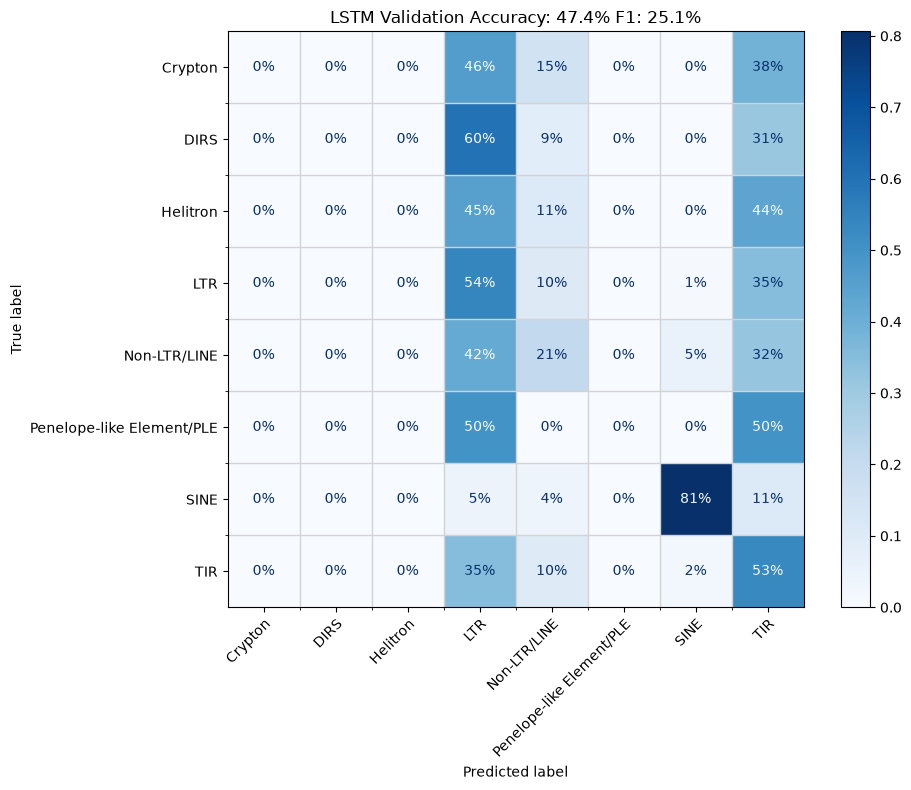

In [14]:
""" Training Cell """ 

# Create model
lstm_classifier = LSTM(input_size, hidden_size, output_size).to(device)

# Initialize the optimizer with the above parameters
optimizer = optim.Adam(lstm_classifier.parameters(), lr=learning_rate)

epoch_loss_logger = []
training_loss_logger = []
training_acc_logger = []
training_f1_logger = []

val_acc_logger = []
val_f1_logger = []

train_f1_metric = F1Score(task="multiclass", num_classes=output_size, average="macro")
train_f1_metric.to(device)

best_val_f1 = 0

final_results_arr = []
final_labels_arr = []
final_val_acc = 0
final_val_f1 = 0


start = time.perf_counter()


for epoch in range(n_epochs):

    print (f"Epoch {epoch}")
    
    # set model to training mode
    lstm_classifier.train()
    steps = 0
    train_acc = 0
    train_f1_metric.reset()
    batch_num = 0

    # Go through training data
    for padded, lengths, labels in data_loader_train:

        padded = padded.to(device)
        labels = labels.to(device)
        
        # Initialize hidden and memory states
        hidden = torch.zeros(num_layers, batch_size, hidden_size, device = device)
        memory = torch.zeros(num_layers, batch_size, hidden_size, device = device)

        # forward pass
        pred, hidden, memory = lstm_classifier(padded, lengths)
    
        # loss calculation
        loss = loss_fn(pred, labels)
        
        # backpropagation and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # append training loss to logger
        epoch_loss_logger.append(loss.item())

        # calculate training accuracy
        train_acc += (pred.argmax(1) == labels).sum()
        steps += len(padded)

        train_f1_metric.update(pred, labels)

        batch_num += 1

    training_loss_logger.append(sum(epoch_loss_logger)/batch_num)

    epoch_loss_logger.clear() 
    
    train_acc = (train_acc/steps).item()
    train_f1 = train_f1_metric.compute().item()
    
    training_acc_logger.append(train_acc)
    training_f1_logger.append(train_f1)

    print(f"Train Acc: {train_acc}")
    print(f"Train F1: {train_f1}")
    
    val_f1, val_acc, results_arr, labels_arr = evaluate(lstm_classifier, data_loader_val)
    final_results_arr = results_arr
    final_labels_arr = labels_arr
    final_val_acc = val_acc
    final_val_f1 = val_f1
    
    val_acc_logger.append(val_acc)
    val_f1_logger.append(val_f1)
    
    print(f"Validation Acc: {val_acc}")
    print(f"Validation F1: {val_f1}\n")

    if val_f1 > best_val_f1:
        print("Found best val_f1, save model weights here")
        torch.save(lstm_classifier.state_dict(), f"{OUT_DIR}lstm_best_learn_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}.pt")
        best_val_f1 = val_f1

    end = time.perf_counter()
    print(f"Elapsed training time : {end - start:.6f} seconds")
    
    print("\n")

df_val_results = make_df_from_results_arrays(final_results_arr, final_labels_arr)
confusion_matrix(
    df_val_results["Actual_Label"], df_val_results["Predicted_Label"].fillna("UNKNOWN"), final_val_acc, final_val_f1, "Validation"
)
    

# Graphs for Accuracy and F1

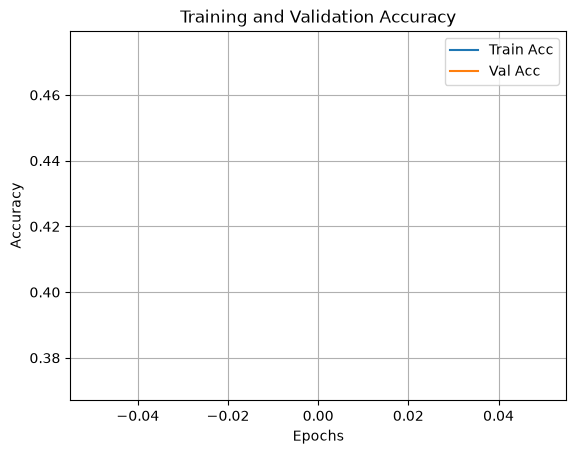

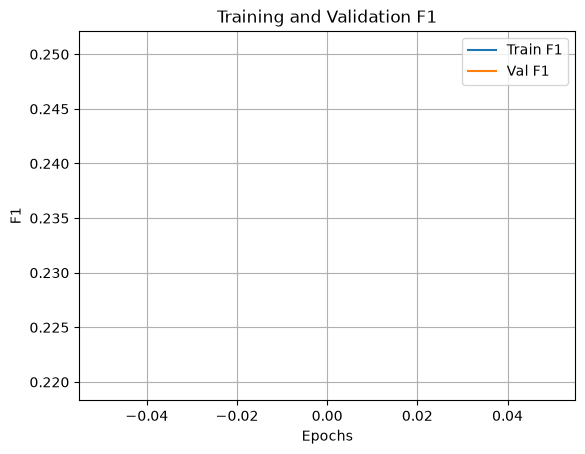

In [15]:
x_labels = np.arange(0, n_epochs)

# _ = plt.figure(figsize=(10, 5))
_ = plt.plot(x_labels, training_acc_logger, label='Train Acc')
_ = plt.plot(x_labels, val_acc_logger, label="Val Acc")

_ = plt.title("Training and Validation Accuracy")
_ = plt.xlabel("Epochs")
_ = plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.savefig(f"{OUT_DIR}train_val_acc_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}_epochs_{n_epochs}.png", dpi=200)
plt.show()




_ = plt.plot(x_labels, training_f1_logger, label="Train F1")
_ = plt.plot(x_labels, val_f1_logger, label="Val F1")

_ = plt.title("Training and Validation F1")
_ = plt.xlabel("Epochs")
_ = plt.ylabel("F1")
plt.grid(True)
plt.legend()
plt.savefig(f"{OUT_DIR}f1_val_acc_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}_epochs_{n_epochs}.png", dpi=200)
plt.show()





# Graph of Loss

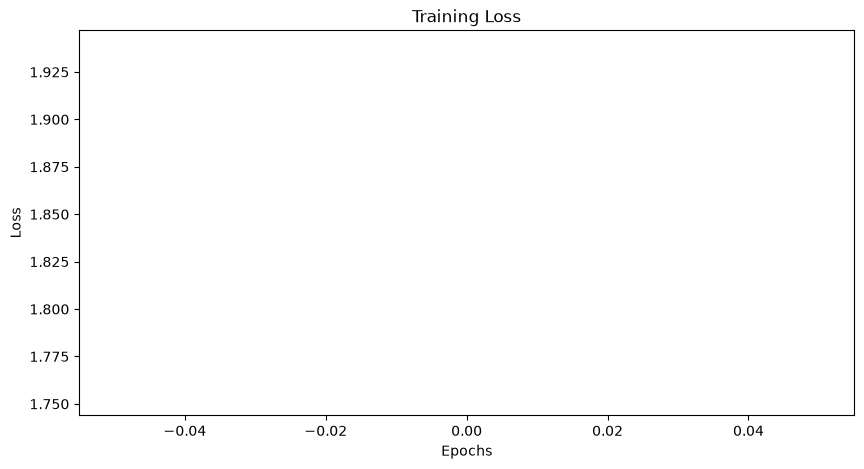

In [16]:
_ = plt.figure(figsize=(10, 5))
_ = plt.plot(np.linspace(0, n_epochs, len(training_loss_logger)), training_loss_logger)

_ = plt.title("Training Loss")
_ = plt.xlabel("Epochs")
_ = plt.ylabel("Loss")
plt.savefig(f"{OUT_DIR}loss_funciton_learn_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}_epochs_{n_epochs}.png", dpi=200)

Testing accuracy: 0.20945945382118225
Testing F1 score: 0.09642153233289719


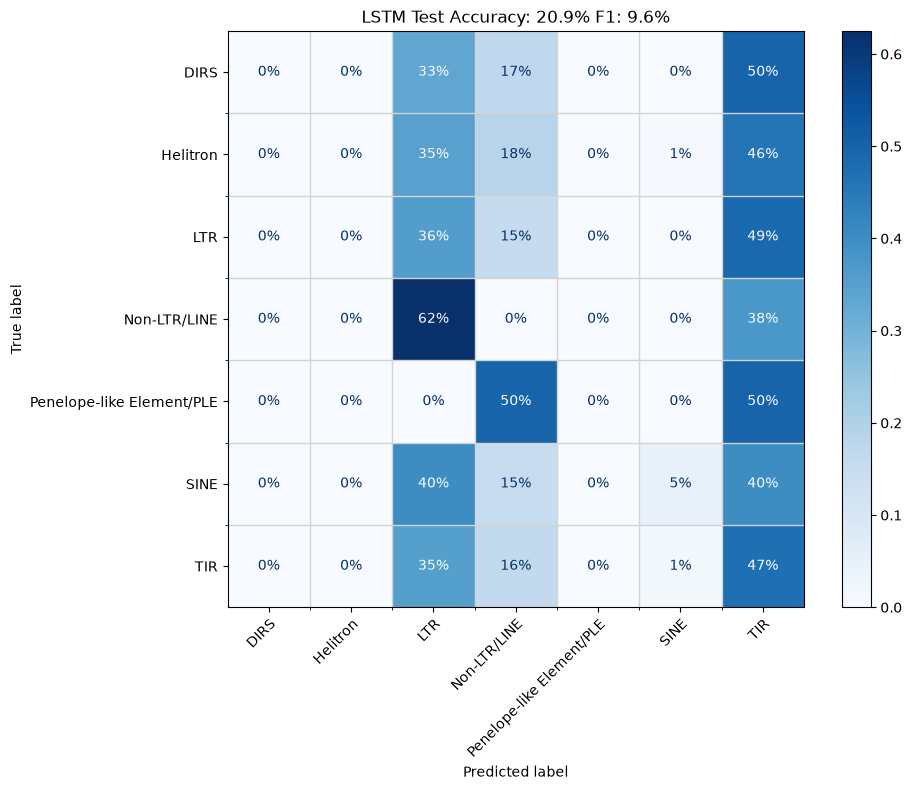

In [17]:
"""
Evaluation with Test Set
"""
lstm_classifier.load_state_dict(torch.load(f"{OUT_DIR}lstm_best_learn_{learning_rate}_MAX_SEQ_{MAX_SEQ_LENGTH}.pt"))
test_f1, test_acc, results_arr, labels_arr = evaluate(lstm_classifier, data_loader_test)
print(f"Testing accuracy: {test_acc}")
print(f"Testing F1 score: {test_f1}")

df_test_results = make_df_from_results_arrays(results_arr, labels_arr)

confusion_matrix(df_test_results["Actual_Label"], df_test_results["Predicted_Label"].fillna("UNKNOWN"), test_acc, test_f1, "Test")